# Bird Occurrence: Target Understanding, EDA and Preprocessing
**Research:** J26-IT-359 | **Dataset:** `data/processed/occurrence/targets_v1/occurrence_training_dataset.csv`

One row represents one **survey checklist × target species**. The verified dataset includes
24 endemic species and a binary Y column, `target_occurrence`: **1 = detected**,
**0 = not detected on an eligible complete checklist**. Zero does not confirm biological absence.

Run the cells from top to bottom in VS Code or Jupyter. The species and Y graphs are in
separate notebook cells, including graphs grouped by the geographic `cell_id`.
No imputation, encoding or scaling is fitted until you define training folds.

This sampling frame comes from the original selected-species observation dataset;
the targets describe detection within those surveys, not national occupancy.
See `data/processed/occurrence/targets_v1/README.md` for the labelling method.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Locate the project from the notebook working directory or any parent directory.
DATA_RELATIVE_PATH = Path('data/processed/occurrence/targets_v1/occurrence_training_dataset.csv')
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / DATA_RELATIVE_PATH).is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f'Cannot find {DATA_RELATIVE_PATH}. Open this notebook from the occurrence_prediction component.'
    )
DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH
OUTPUT = DATA_PATH.parent / 'preprocessing'
OUTPUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
required = {'checklist_id', 'survey_group_id', 'scientific_name', 'cell_id',
            'target_occurrence', 'survey_distance_km', 'hours_of_day', 'number_observers'}
if required - set(df.columns):
    raise ValueError(f'Missing required columns: {sorted(required - set(df.columns))}')
if df['target_occurrence'].isna().any() or not df['target_occurrence'].isin([0, 1]).all():
    raise ValueError('The training table must contain only verified binary Y values (0 or 1).')
df['target_occurrence'] = df['target_occurrence'].astype('int8')
survey_df = df.drop_duplicates('checklist_id').copy()
print('Dataset:', DATA_PATH)
print('Shape:', df.shape, '| Species:', df['scientific_name'].nunique())
print('Independent surveys:', survey_df['survey_group_id'].nunique())
print('Outputs created when you run this notebook:', OUTPUT)
display(df.head())

ModuleNotFoundError: No module named 'pandas'

## 1. Data understanding
The prediction unit is a **checklist–species pair**. A checklist appears once for each target
species, including species not detected there. `target_occurrence` is Y; `scientific_name`
identifies which species is being predicted. `all_species_reported` is checklist completeness,
not Y. Survey identifiers and `cell_id` are retained for grouping and validation.
The labelling release already selects one eligible representative per shared survey group.

In [ ]:
print('Rows:', len(df), '| Columns:', len(df.columns))
print('Column names:')
print(df.columns.tolist())
print('Data types:')
print(df.dtypes)
print('Summary of numeric columns:')
display(df.describe().T)
print('Summary of categorical columns:')
display(df.describe(include='object').T)
print('\nSpecies:', df['scientific_name'].nunique())
print('Checklists:', df['checklist_id'].nunique())
print('Geographic cells:', df['cell_id'].nunique())
print('Years:', sorted(df['year'].unique()))
print('Y counts:', df['target_occurrence'].value_counts().sort_index().to_dict())

Rows: 505608 | Columns: 24
Column names:
['checklist_id', 'survey_group_id', 'scientific_name', 'observation_date', 'year', 'month', 'cell_id', 'latitude', 'longitude', 'temperature_mean_c', 'rainfall_mm', 'elevation_m', 'ndvi', 'land_cover', 'duration_minutes', 'effort_distance_km', 'survey_distance_km', 'protocol', 'all_species_reported', 'hours_of_day', 'number_observers', 'effort_speed_kmph', 'target_occurrence', 'label_status']
Data types:
checklist_id             object
survey_group_id          object
scientific_name          object
observation_date         object
year                      int64
month                     int64
cell_id                  object
latitude                float64
longitude               float64
temperature_mean_c      float64
rainfall_mm             float64
elevation_m             float64
ndvi                    float64
land_cover               object
duration_minutes        float64
effort_distance_km      float64
survey_distance_km      float64
protoco

,count,mean,std,min,25%,50%,75%,max
year,505608.0,2020.699388,2.178569,2010.000000,2020.000000,2021.000000,2022.000000,2023.000000
month,505608.0,5.959890,3.633332,1.000000,3.000000,5.000000,9.000000,12.000000
latitude,505608.0,6.784404,0.585107,5.927466,6.377266,6.830337,7.012474,9.814162
longitude,505608.0,80.366334,0.388940,79.696504,79.985176,80.384700,80.598106,81.835245
temperature_mean_c,505608.0,25.612152,2.280918,17.200000,25.000000,26.200000,27.100000,31.100000
rainfall_mm,505608.0,5.656543,9.138255,0.000000,0.600000,2.600000,7.000000,177.600000
elevation_m,504720.0,225.616833,406.724252,0.000000,13.000000,28.000000,234.000000,2486.000000
ndvi,322248.0,0.717936,0.122774,-0.195700,0.646600,0.743400,0.814000,0.965900
duration_minutes,505608.0,79.486970,77.232747,1.000000,25.000000,54.000000,116.000000,360.000000
effort_distance_km,287232.0,2.109539,2.279731,0.001000,0.500000,1.270000,3.000000,10.000000


Summary of categorical columns:


,count,unique,top,freq
checklist_id,505608,21067,S100000513,24
survey_group_id,505608,21067,S100000513,24
scientific_name,505608,24,Argya cinereifrons,21067
observation_date,505608,2824,2023-05-13,1632
cell_id,505608,954,lka_laea_5000m_-18_-20,29280
land_cover,505560,24,ESRI_7,158304
protocol,505608,2,Traveling,287232
label_status,505608,2,verified_non_detection,451395



Species: 24
Checklists: 21067
Geographic cells: 954
Years: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Y counts: {0: 451395, 1: 54213}


## 2. Missing-value analysis
These percentages describe the labelled training table. Keep Y unchanged and keep
environmental missingness separate from whether a bird was detected.

,missing_count,missing_percent
effort_distance_km,218376,43.19
ndvi,183360,36.27
elevation_m,888,0.18
land_cover,48,0.01
target_occurrence,0,0.00
effort_speed_kmph,0,0.00
number_observers,0,0.00
hours_of_day,0,0.00
all_species_reported,0,0.00
protocol,0,0.00


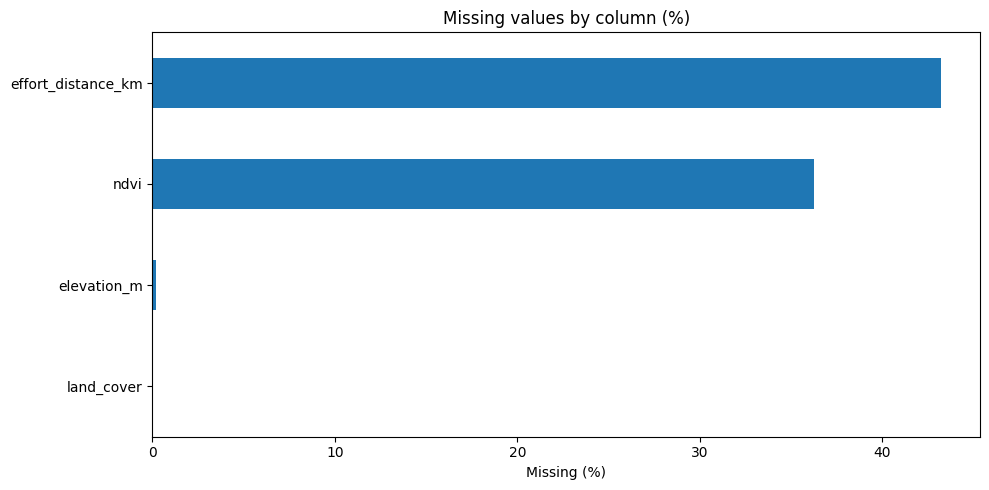

In [ ]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2)
}).sort_values('missing_count', ascending=False)
display(missing)
missing.to_csv(OUTPUT / 'missing_value_report.csv')
plt.figure(figsize=(10, 5))
missing[missing.missing_count > 0]['missing_percent'].sort_values().plot(kind='barh')
plt.title('Missing values by column (%)')
plt.xlabel('Missing (%)')
plt.tight_layout()
plt.show()

### Missing-data decisions
- `target_occurrence`: verified binary labels are already supplied. Never impute Y.
- `cell_id` and survey identifiers: never fill with numeric averages; retain them for validation.
- `elevation_m` and `ndvi`: preserve missingness, then fit median imputation on training folds only.
- `land_cover`: retain source-prefixed classifications. The source changes in 2021;
  encoding does not make the two classifications scientifically equivalent.
- `effort_distance_km`: stationary blanks are not unknown traveling distances.
  Use the verified derived `survey_distance_km` feature, whose stationary value is structurally zero.
- Do not drop every row with an environmental gap or alter Y because an environmental measurement is missing.